# Bài 2. Xử lý ảnh hình thái học

**Nội dung:** (1) tự lập trình erosion / dilation / opening / closing bằng NumPy và đối chiếu với OpenCV;
(2) thử nghiệm các phần tử cấu trúc (SE) khác hình dạng, kích thước; (3) cài đặt các thuật toán hình thái:
trích xuất hình bao (boundary), làm đầy lỗ (hole filling), thành phần liên thông (connected components),
convex hull và thinning.

**Ảnh đầu vào:** `coins.png` (303×384, xám - ảnh mẫu scikit-image, đồng xu trên nền tối) và `page.png`
(ảnh trang chữ in, dùng cho thinning). Ảnh nhị phân được tạo bằng ngưỡng Otsu.

In [1]:
# ===== Cài đặt & hàm tiện ích dùng chung =====
import os, time, warnings
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data, color, filters, morphology, measure, segmentation, util
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 80, "font.size": 9, "axes.titlesize": 9})

# Thư mục ảnh đầu vào / kết quả.
# Muốn dùng ảnh trong bộ dữ liệu LMS: chép ảnh vào images/ và đổi tên file ở ô "Ảnh đầu vào".
IMG_DIR, OUT_DIR = "images", "outputs/bai2"
for d in (IMG_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)


def load_rgb(name, fallback, max_side=None):
    """Đọc ảnh màu RGB từ images/<name>; nếu chưa có thì lấy ảnh mẫu rồi lưu lại."""
    p = os.path.join(IMG_DIR, name)
    if not os.path.exists(p):
        cv2.imwrite(p, cv2.cvtColor(fallback(), cv2.COLOR_RGB2BGR))
    img = cv2.cvtColor(cv2.imread(p, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    if max_side and max(img.shape[:2]) > max_side:
        s = max_side / max(img.shape[:2])
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return img


def load_gray(name, fallback, max_side=None):
    """Đọc ảnh xám uint8 từ images/<name>; nếu chưa có thì lấy ảnh mẫu rồi lưu lại."""
    p = os.path.join(IMG_DIR, name)
    if not os.path.exists(p):
        cv2.imwrite(p, fallback())
    img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    if max_side and max(img.shape) > max_side:
        s = max_side / max(img.shape)
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return img


def show(images, titles=None, ncols=4, name=None, cell=3.0, cmap="gray"):
    """Hiển thị lưới ảnh; ảnh 2-D hiển thị theo thang xám cố định; lưu vào OUT_DIR/name."""
    n = len(images)
    ncols = min(ncols, n)
    nrows = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(cell * ncols, (cell * images[0].shape[0] / images[0].shape[1] + 0.35) * nrows), squeeze=False)
    for i, ax in enumerate(axs.ravel()):
        ax.axis("off")
        if i >= n:
            continue
        im = images[i]
        if im.ndim == 2:
            if im.dtype == np.uint8:
                ax.imshow(im, cmap=cmap, vmin=0, vmax=255)
            elif im.dtype == bool:
                ax.imshow(im, cmap=cmap, vmin=0, vmax=1)
            else:
                ax.imshow(im, cmap=cmap)
        else:
            ax.imshow(im)
        if titles is not None:
            ax.set_title(titles[i])
    fig.tight_layout()
    if name:
        fig.savefig(os.path.join(OUT_DIR, name), dpi=110, bbox_inches="tight")
    plt.show()


## 2.0 Ảnh đầu vào và ảnh nhị phân

Kích thước: (303, 384) | ngưỡng Otsu = 107.0 | số điểm trắng = 45117


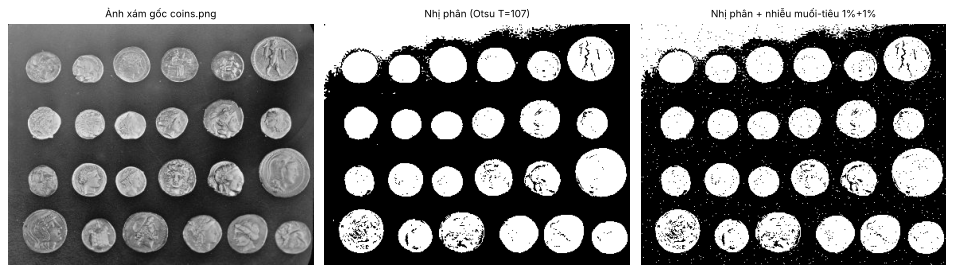

In [2]:
coins = load_gray("coins.png", data.coins)
T_otsu, bw = cv2.threshold(coins, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)   # 0/255, uint8
print("Kích thước:", coins.shape, "| ngưỡng Otsu =", T_otsu, "| số điểm trắng =", int((bw > 0).sum()))

# ảnh nhị phân có thêm nhiễu muối-tiêu (dùng để thử opening/closing)
rng = np.random.default_rng(0)
noisy = bw.copy()
r = rng.random(bw.shape)
noisy[r < 0.01] = 255          # nhiễu muối (điểm trắng)
noisy[r > 0.99] = 0            # nhiễu tiêu (điểm đen)
show([coins, bw, noisy], ["Ảnh xám gốc coins.png", f"Nhị phân (Otsu T={int(T_otsu)})", "Nhị phân + nhiễu muối-tiêu 1%+1%"],
     ncols=3, cell=4, name="b2_input.png")

## 2.1 Tự lập trình erosion, dilation, opening, closing bằng NumPy

* Phần tử cấu trúc `se` (ma trận 0/1, gốc ở tâm). Với mỗi điểm 1 của `se` ta dịch ảnh một đoạn tương ứng rồi
  lấy **min** (erosion) hoặc **max** (dilation) trên các ảnh đã dịch -> vector hóa toàn ảnh, không cần vòng lặp theo pixel.
* Erosion: $(f\ominus B)(x)=\min_{s\in B} f(x+s)$; Dilation: $(f\oplus B)(x)=\max_{s\in B} f(x-s)$ (SE được **lật** qua gốc).
* Biên ảnh: erosion đệm giá trị lớn nhất (255), dilation đệm 0 (giống mặc định của OpenCV).
* Opening = dilation(erosion(f)); Closing = erosion(dilation(f)). Cùng một code chạy cho ảnh nhị phân (0/255) lẫn ảnh xám.

**Tham số:** hình dạng và kích thước SE (`make_se(shape, size)`).

In [3]:
def make_se(shape, size):
    """Phần tử cấu trúc kích thước size x size (size lẻ)."""
    c = size // 2
    if shape == "rect":
        return np.ones((size, size), np.uint8)
    if shape == "ellipse":
        return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
    if shape == "cross":
        return cv2.getStructuringElement(cv2.MORPH_CROSS, (size, size))
    if shape == "diamond":
        yy, xx = np.ogrid[:size, :size]
        return (np.abs(yy - c) + np.abs(xx - c) <= c).astype(np.uint8)
    se = np.zeros((size, size), np.uint8)
    if shape == "hline":
        se[c, :] = 1
    elif shape == "vline":
        se[:, c] = 1
    else:
        raise ValueError(shape)
    return se


def se_img(se):
    """Ảnh minh họa SE: ô thuộc SE màu trắng, ô ngoài SE màu đen, viền xám để thấy rõ khung."""
    c = np.full((se.shape[0] + 2, se.shape[1] + 2), 90, np.uint8)
    c[1:-1, 1:-1] = se * 255
    return cv2.resize(c, None, fx=8, fy=8, interpolation=cv2.INTER_NEAREST)


def _shifted(img, se, pad_value):
    """Sinh các bản dịch của ảnh tương ứng với từng điểm 1 của se (se có gốc ở tâm)."""
    kh, kw = se.shape
    cy, cx = kh // 2, kw // 2
    p = np.pad(img, ((cy, kh - 1 - cy), (cx, kw - 1 - cx)), constant_values=pad_value)
    H, W = img.shape
    for dy, dx in zip(*np.nonzero(se)):
        yield p[dy:dy + H, dx:dx + W]


def erosion(img, se):
    out = None
    for s in _shifted(img, se, 255):
        out = s.copy() if out is None else np.minimum(out, s)
    return out


def dilation(img, se):
    se_r = se[::-1, ::-1]                     # dilation dùng SE lấy đối xứng qua gốc
    out = None
    for s in _shifted(img, se_r, 0):
        out = s.copy() if out is None else np.maximum(out, s)
    return out


def opening(img, se):
    return dilation(erosion(img, se), se)


def closing(img, se):
    return erosion(dilation(img, se), se)


def timeit(fn, *a, rep=5):
    t = time.perf_counter()
    for _ in range(rep):
        r = fn(*a)
    return r, (time.perf_counter() - t) / rep * 1000   # ms

### So sánh với OpenCV (ảnh nhị phân và ảnh xám, nhiều SE)
`np.array_equal` = True nghĩa là kết quả **trùng khít từng pixel**.

In [4]:
ops = {
    "erosion":  (erosion,  lambda im, k: cv2.erode(im, k)),
    "dilation": (dilation, lambda im, k: cv2.dilate(im, k)),
    "opening":  (opening,  lambda im, k: cv2.morphologyEx(im, cv2.MORPH_OPEN, k)),
    "closing":  (closing,  lambda im, k: cv2.morphologyEx(im, cv2.MORPH_CLOSE, k)),
}
print(f"{'ảnh':8s} {'SE':12s} {'phép':9s} {'giống OpenCV':13s} {'t_NumPy(ms)':>12s} {'t_OpenCV(ms)':>13s}")
all_equal = True
for img_name, img in [("nhị phân", noisy), ("xám", coins)]:
    for shape, size in [("rect", 3), ("ellipse", 7), ("cross", 5), ("rect", 15)]:
        se = make_se(shape, size)
        for op, (mine, ref) in ops.items():
            a, t1 = timeit(mine, img, se)
            b, t2 = timeit(ref, img, se)
            eq = np.array_equal(a, b)
            all_equal &= eq
            print(f"{img_name:8s} {shape + str(size):12s} {op:9s} {str(eq):13s} {t1:12.2f} {t2:13.3f}")
print("\n=> Tất cả trường hợp trùng OpenCV:", all_equal)

# SE bất đối xứng: dilation của ta (SE được lật) = cv2.dilate với SE đã lật
se_asym = np.array([[1, 0, 0], [1, 1, 0], [0, 0, 0]], np.uint8)
print("SE bất đối xứng - dilation trùng cv2.dilate(SE lật):",
      np.array_equal(dilation(bw, se_asym), cv2.dilate(bw, se_asym[::-1, ::-1])))

ảnh      SE           phép      giống OpenCV   t_NumPy(ms)  t_OpenCV(ms)
nhị phân rect3        erosion   True                  0.47         0.053
nhị phân rect3        dilation  True                  0.23         0.037
nhị phân rect3        opening   True                  0.39         0.061
nhị phân rect3        closing   True                  0.44         0.061
nhị phân ellipse7     erosion   True                  0.54         0.081
nhị phân ellipse7     dilation  True                  0.52         0.080
nhị phân ellipse7     opening   True                  1.00         0.145
nhị phân ellipse7     closing   True                  1.01         0.176
nhị phân cross5       erosion   True                  0.21         0.034
nhị phân cross5       dilation  True                  0.20         0.052
nhị phân cross5       opening   True                  0.63         0.064
nhị phân cross5       closing   True                  0.71         0.114
nhị phân rect15       erosion   True               

xám      rect15       erosion   True                  4.48         0.110
xám      rect15       dilation  True                  4.21         0.076
xám      rect15       opening   True                  7.55         0.126
xám      rect15       closing   True                  5.86         0.138

=> Tất cả trường hợp trùng OpenCV: True
SE bất đối xứng - dilation trùng cv2.dilate(SE lật): True


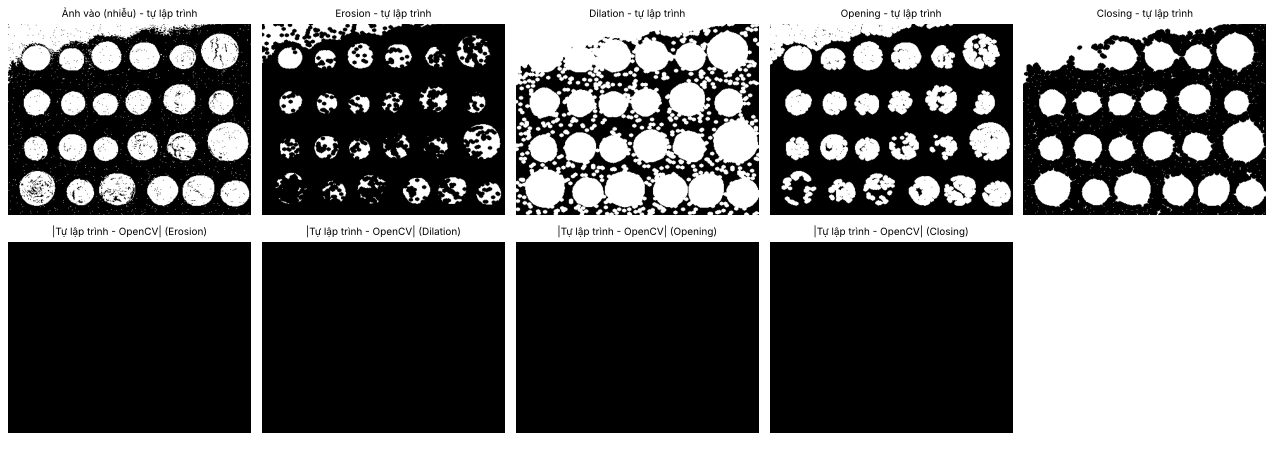

Tổng sai khác tuyệt đối so với OpenCV: [0, 0, 0, 0]


In [5]:
se = make_se("ellipse", 7)
res = [noisy, erosion(noisy, se), dilation(noisy, se), opening(noisy, se), closing(noisy, se)]
cvr = [noisy, cv2.erode(noisy, se), cv2.dilate(noisy, se), cv2.morphologyEx(noisy, cv2.MORPH_OPEN, se),
       cv2.morphologyEx(noisy, cv2.MORPH_CLOSE, se)]
tt = ["Ảnh vào (nhiễu)", "Erosion", "Dilation", "Opening", "Closing"]
show(res + [np.abs(a.astype(int) - b.astype(int)).astype(np.uint8) * 255 for a, b in zip(res[1:], cvr[1:])],
     [t + " - tự lập trình" for t in tt] + [f"|Tự lập trình - OpenCV| ({t})" for t in tt[1:]],
     ncols=5, cell=3.2, name="b2_vs_opencv.png")
print("Tổng sai khác tuyệt đối so với OpenCV:", [int(np.abs(a.astype(int) - b.astype(int)).sum()) for a, b in zip(res[1:], cvr[1:])])

**Nhận xét 2.1**
* Cả 32 trường hợp thử (2 ảnh: nhị phân và xám × 4 SE × 4 phép) cho kết quả **trùng OpenCV từng pixel** (tổng sai khác tuyệt đối = 0). Với SE bất đối xứng, dilation phải dùng SE đã lật qua gốc (định nghĩa chuẩn); khi đó mới trùng `cv2.dilate` với SE lật - đã kiểm chứng.
* Cách vector hóa (min/max trên các bản dịch) chạy được cho cả ảnh nhị phân và ảnh xám với cùng một đoạn mã. Thời gian NumPy 0,2 - 6 ms, OpenCV 0,03 - 0,15 ms, tức chậm hơn khoảng 6 - 50 lần: chi phí tăng tuyến tính theo số điểm của SE (rect 3×3 = 9 điểm ≈ 0,2 - 0,4 ms; rect 15×15 = 225 điểm ≈ 3 - 6 ms), còn OpenCV dùng SIMD và phân tách SE chữ nhật. Opening/closing tốn gấp đôi erosion/dilation.

## 2.2 Thử nghiệm phần tử cấu trúc khác hình dạng và kích thước

**(a)** Cố định kích thước 7, đổi hình dạng SE (rect / ellipse / cross / diamond / hline / vline).
**(b)** Cố định hình ellipse, đổi kích thước 3, 7, 15, 25. Ảnh vào là ảnh nhị phân có nhiễu muối-tiêu.

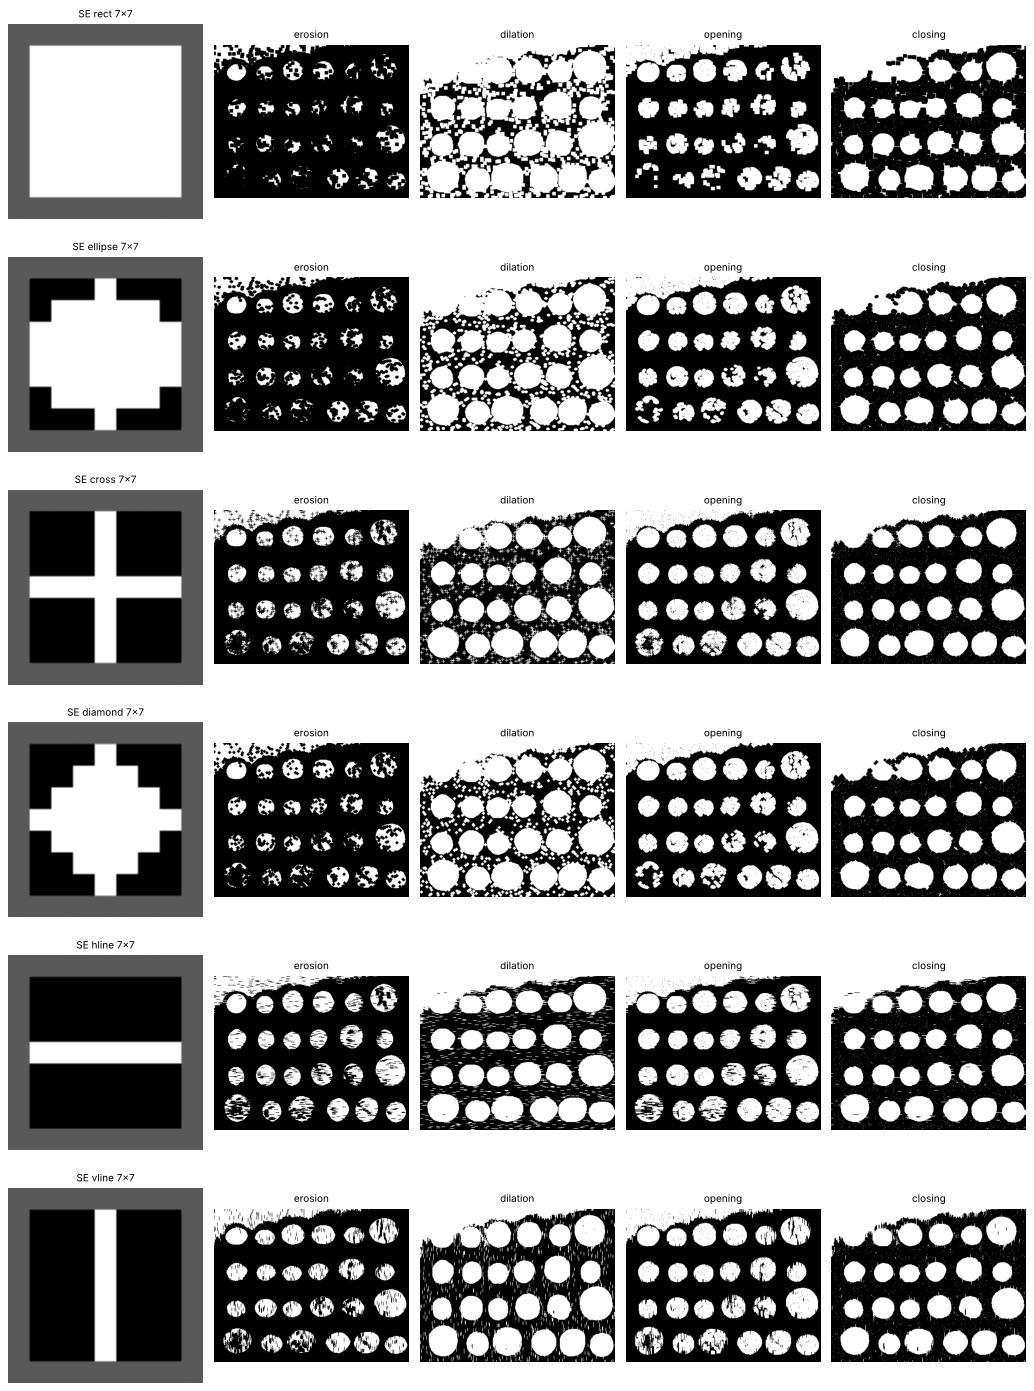

In [6]:
shapes = ["rect", "ellipse", "cross", "diamond", "hline", "vline"]
imgs, tits = [], []
for sh in shapes:
    se = make_se(sh, 7)
    imgs += [se_img(se), erosion(noisy, se), dilation(noisy, se), opening(noisy, se), closing(noisy, se)]
    tits += [f"SE {sh} 7x7", "erosion", "dilation", "opening", "closing"]
show(imgs, tits, ncols=5, cell=2.6, name="b2_se_shapes.png")

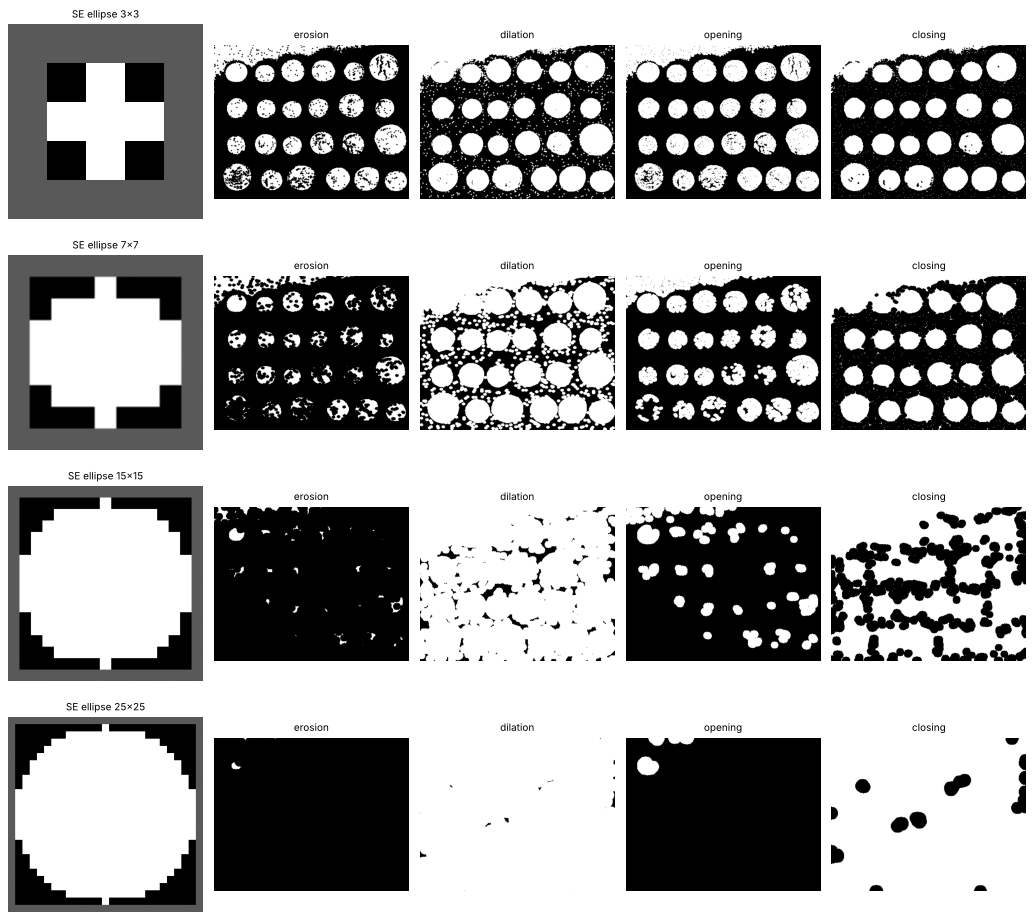

Ảnh sạch: diện tích = 45117, số thành phần = 96
SE             phép       diện tích  số TP liên thông   sai khác so với ảnh sạch (px)
rect3          opening        42772                36                            2395
rect3          closing        48140               583                            3053
ellipse7       opening        38118                39                            7023
ellipse7       closing        50234               464                            5145
ellipse15      opening        16097                28                           29020
ellipse15      closing        72610                45                           27505
ellipse25      opening         2177                 3                           42940
ellipse25      closing       108987                 1                           63870
cross7         opening        41558                27                            3625
cross7         closing        48517               652                            3464
hline7

In [7]:
sizes = [3, 7, 15, 25]
imgs, tits = [], []
for sz in sizes:
    se = make_se("ellipse", sz)
    imgs += [se_img(se), erosion(noisy, se), dilation(noisy, se), opening(noisy, se), closing(noisy, se)]
    tits += [f"SE ellipse {sz}x{sz}", "erosion", "dilation", "opening", "closing"]
show(imgs, tits, ncols=5, cell=2.6, name="b2_se_sizes.png")

# bảng định lượng: diện tích vùng trắng (so với ảnh nhị phân sạch) và số thành phần liên thông
clean_area = int((bw > 0).sum())
n_clean = cv2.connectedComponents(bw, connectivity=8)[0] - 1
print(f"Ảnh sạch: diện tích = {clean_area}, số thành phần = {n_clean}")
print(f"{'SE':14s} {'phép':9s} {'diện tích':>10s} {'số TP liên thông':>17s} {'sai khác so với ảnh sạch (px)':>31s}")
for sh, sz in [("rect", 3), ("ellipse", 7), ("ellipse", 15), ("ellipse", 25), ("cross", 7), ("hline", 7)]:
    se = make_se(sh, sz)
    for op in ("opening", "closing"):
        o = (opening if op == "opening" else closing)(noisy, se)
        ncc = cv2.connectedComponents(o, connectivity=8)[0] - 1
        print(f"{sh + str(sz):14s} {op:9s} {int((o > 0).sum()):10d} {ncc:17d} {int((o != bw).sum()):31d}")

**Nhận xét 2.2**
* **Hình dạng SE (7×7):** `rect` làm điểm nhiễu nở thành khối vuông góc nhọn; `ellipse` và `diamond` cho đốm tròn/thoi mượt hơn, ít làm méo hình tròn của đồng xu; `cross` có ít điểm nhất nên tác động nhẹ nhất (nhiễu nở thành dấu cộng mảnh); `hline`/`vline` có tính **định hướng**: nhiễu bị kéo thành vạch ngang/dọc và phép toán chỉ ảnh hưởng theo một phương (vd. erosion bằng `hline` chỉ cắt nét hẹp theo chiều ngang, các vệt xuất hiện song song nhau trong đồng xu). Chọn SE nên bám theo hình dạng đối tượng cần giữ.
* **Kích thước SE (ellipse) - opening:** 3×3: còn 36 thành phần, diện tích 42 772 px (lệch 2 395 px so với ảnh sạch) - diệt nhiễu muối tốt mà ít hỏng đối tượng; 7×7: 39 thành phần (lệch 7 023 px); 15×15: diện tích chỉ còn 16 097 px (lệch 29 020 px) vì mảng sáng nhỏ của đồng xu bị loại; 25×25: chỉ còn 3 thành phần (2 177 px) - SE lớn hơn đa số đối tượng thì opening xóa chúng.
* **Closing:** SE 3×3, 7×7 vẫn còn 583 và 464 thành phần vì closing chỉ lấp nhiễu tiêu (điểm đen), **không loại được nhiễu muối** (điểm trắng) - đối ngẫu của opening; 15×15: diện tích phình ra 72 610 px; 25×25: dính toàn bộ đồng xu và nền thành 1 thành phần (108 987 px). Kết luận: SE phải *lớn hơn nhiễu nhưng nhỏ hơn chi tiết cần giữ*; dùng opening để loại nhiễu muối/vật nhỏ, closing để lấp lỗ/khe nhỏ, và mở rồi đóng (opening -> closing) để xử lý nhiễu muối-tiêu.

## 2.3 Các thuật toán hình thái học

Ảnh nhị phân đã làm sạch: `clean = closing(opening(noisy, ellipse 5), ellipse 5)`; đây là đầu vào cho các thuật toán dưới đây.
Tự lập trình: **trích xuất hình bao**, **làm đầy lỗ**, **thành phần liên thông**. Dùng thư viện để đối chiếu:
**convex hull**, **thinning**.

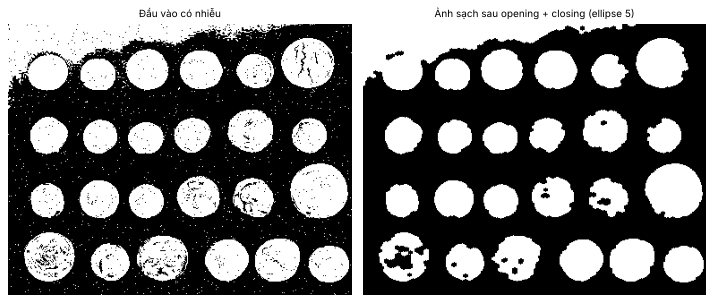

In [8]:
se5 = make_se("ellipse", 5)
clean = closing(opening(noisy, se5), se5)
show([noisy, clean], ["Đầu vào có nhiễu", "Ảnh sạch sau opening + closing (ellipse 5)"], ncols=2, cell=4.5, name="b2_clean.png")

### (1) Trích xuất hình bao (boundary extraction)
$\beta(A)=A-(A\ominus B)$ với $B$ là SE 3×3 (hình bao dày 1 px). Tham số: SE `rect 3` (8-liên thông) và `cross 3` (4-liên thông).

Số pixel hình bao: SE rect3 = 5364 | SE cross3 = 3897
Khác biệt với skimage.find_boundaries (mode=inner): rect3 -> 0 px, cross3 -> 0 px


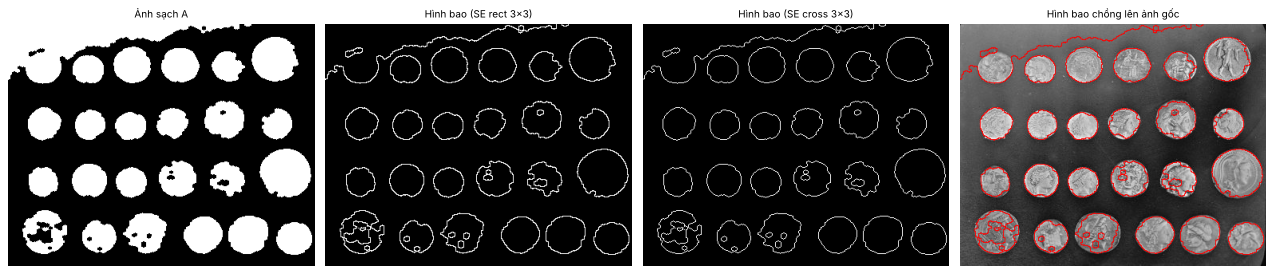

In [9]:
def boundary(A, se):
    return cv2.subtract(A, erosion(A, se))      # A - (A erosion B)

b8 = boundary(clean, make_se("rect", 3))
b4 = boundary(clean, make_se("cross", 3))
# đối chiếu: hình bao trong của scikit-image
ref8 = segmentation.find_boundaries(clean > 0, connectivity=2, mode="inner")
ref4 = segmentation.find_boundaries(clean > 0, connectivity=1, mode="inner")
print("Số pixel hình bao: SE rect3 =", int((b8 > 0).sum()), "| SE cross3 =", int((b4 > 0).sum()))
print("Khác biệt với skimage.find_boundaries (mode=inner): rect3 ->", int(((b8 > 0) != ref8).sum()),
      "px, cross3 ->", int(((b4 > 0) != ref4).sum()), "px")
overlay = cv2.cvtColor(coins, cv2.COLOR_GRAY2RGB)
overlay[b8 > 0] = (255, 0, 0)
show([clean, b8, b4, overlay], ["Ảnh sạch A", "Hình bao (SE rect 3x3)", "Hình bao (SE cross 3x3)", "Hình bao chồng lên ảnh gốc"],
     ncols=4, cell=4, name="b2_boundary.png")

### (2) Làm đầy lỗ (hole filling)
Cách tự động (không cần chọn điểm gốc): nền liên thông với biên ảnh được dựng lại bằng giãn có điều kiện
$X_k=(X_{k-1}\oplus B)\cap A^c$ với $X_0$ = các điểm nền nằm trên biên ảnh, $B$ = SE chữ thập (4-liên thông).
Các lỗ = $A^c - X_\infty$; ảnh đã đầy = $A \cup$ lỗ. Lặp đến khi hội tụ.

Số vòng lặp hội tụ: 205 | diện tích lỗ = 956 px | khác scipy.ndimage.binary_fill_holes: 0 px


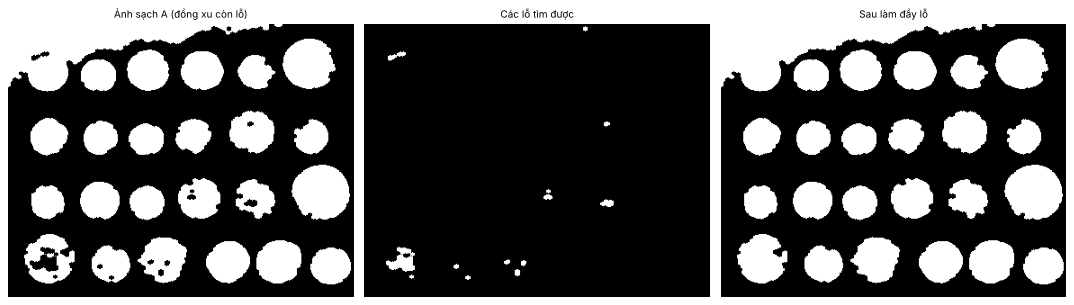

In [10]:
def fill_holes(A, se=None):
    se = make_se("cross", 3) if se is None else se
    Ac = 255 - A
    X = np.zeros_like(A)
    X[0, :], X[-1, :], X[:, 0], X[:, -1] = Ac[0, :], Ac[-1, :], Ac[:, 0], Ac[:, -1]   # nền chạm biên ảnh
    it = 0
    while True:
        Xn = cv2.bitwise_and(dilation(X, se), Ac)
        it += 1
        if np.array_equal(Xn, X):
            break
        X = Xn
    holes = cv2.subtract(Ac, X)
    return cv2.bitwise_or(A, holes), holes, it

from scipy import ndimage as ndi
filled, holes, n_it = fill_holes(clean)
ref = ndi.binary_fill_holes(clean > 0)
print(f"Số vòng lặp hội tụ: {n_it} | diện tích lỗ = {int((holes > 0).sum())} px | "
      f"khác scipy.ndimage.binary_fill_holes: {int(((filled > 0) != ref).sum())} px")
show([clean, holes, filled], ["Ảnh sạch A (đồng xu còn lỗ)", "Các lỗ tìm được", "Sau làm đầy lỗ"], ncols=3, cell=4.5, name="b2_fill.png")

### (3) Thành phần liên thông (connected components)
Lấy một điểm chưa gán nhãn làm hạt $X_0$, lặp $X_k=(X_{k-1}\oplus B)\cap A$ đến khi hội tụ; $X_\infty$ là một thành phần.
Lặp cho đến hết điểm trắng. $B$ = `rect 3x3` (8-liên thông) hoặc `cross 3x3` (4-liên thông). Đối chiếu `cv2.connectedComponents`.

Tự lập trình: 8-liên thông = 26 TP, 4-liên thông = 27 TP   (thời gian 0.60s)
Hai khối chéo đặt tại (y=157, x=54): 8-conn gộp thành 1 TP, 4-conn tách thành 2 TP
OpenCV      : 8-liên thông = 26 TP, 4-liên thông = 27 TP
Phân hoạch giống OpenCV: 8-conn = True | 4-conn = True
Diện tích các TP (8-conn): [18, 23, 1074, 1075, 1078, 1097, 1107, 1116, 1121, 1138, 1295, 1302, 1335, 1448, 1455, 1620, 1623, 1663, 1717, 1800, 1911, 1933, 2187, 2490, 3024, 8473]


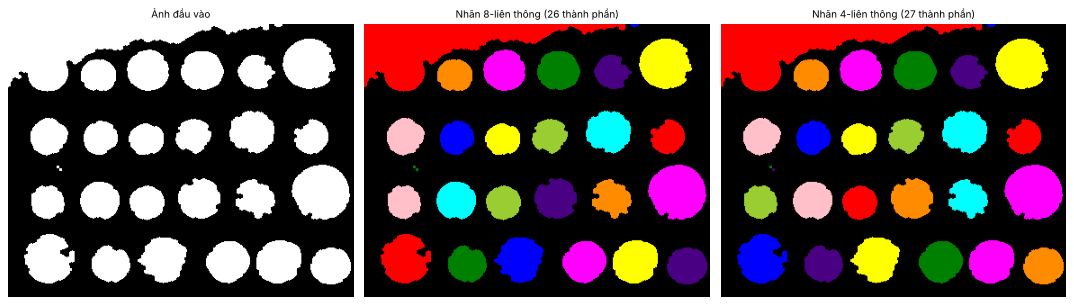

In [11]:
def connected_components(A, se):
    remaining = A > 0
    labels = np.zeros(A.shape, np.int32)
    n = 0
    while remaining.any():
        ys, xs = np.nonzero(remaining)
        X = np.zeros_like(A)
        X[ys[0], xs[0]] = 255
        while True:
            Xn = cv2.bitwise_and(dilation(X, se), A)
            if np.array_equal(Xn, X):
                break
            X = Xn
        n += 1
        labels[X > 0] = n
        remaining &= ~(X > 0)
    return n, labels

def same_partition(l1, l2):
    """Hai ảnh nhãn là một phép phân hoạch giống nhau (không phụ thuộc số thứ tự nhãn)."""
    pairs = set(zip(l1.ravel().tolist(), l2.ravel().tolist()))
    return len(pairs) == len(set(p[0] for p in pairs)) == len(set(p[1] for p in pairs))

# ảnh thử: ảnh sạch đã làm đầy lỗ, thêm vài vật nhỏ chạm chéo để thấy khác biệt 4/8-liên thông
test = filled.copy()
free = np.argwhere(erosion(255 - filled, make_se("rect", 9)) > 0)   # vùng nền trống 9x9
y0, x0 = free[len(free) // 2]
test[y0:y0 + 3, x0:x0 + 3] = 255
test[y0 + 3:y0 + 6, x0 + 3:x0 + 6] = 255   # hai khối 3x3 chỉ chạm nhau ở góc chéo
t0 = time.perf_counter()
n8, lab8 = connected_components(test, make_se("rect", 3))
n4, lab4 = connected_components(test, make_se("cross", 3))
t_my = time.perf_counter() - t0
cv8 = cv2.connectedComponents(test, connectivity=8)
cv4 = cv2.connectedComponents(test, connectivity=4)
print(f"Tự lập trình: 8-liên thông = {n8} TP, 4-liên thông = {n4} TP   (thời gian {t_my:.2f}s)")
print(f"Hai khối chéo đặt tại (y={y0}, x={x0}): 8-conn gộp thành 1 TP, 4-conn tách thành 2 TP")
print(f"OpenCV      : 8-liên thông = {cv8[0]-1} TP, 4-liên thông = {cv4[0]-1} TP")
print("Phân hoạch giống OpenCV: 8-conn =", same_partition(lab8, cv8[1]), "| 4-conn =", same_partition(lab4, cv4[1]))
props = measure.regionprops(lab8)
print("Diện tích các TP (8-conn):", sorted(int(p.area) for p in props))
rgb8 = (color.label2rgb(lab8, bg_label=0, bg_color=(0, 0, 0)) * 255).astype(np.uint8)
show([test, rgb8, (color.label2rgb(lab4, bg_label=0, bg_color=(0, 0, 0)) * 255).astype(np.uint8)],
     ["Ảnh đầu vào", f"Nhãn 8-liên thông ({n8} thành phần)", f"Nhãn 4-liên thông ({n4} thành phần)"], ncols=3, cell=4.5, name="b2_cc.png")

### (4) Convex hull
Với mỗi thành phần liên thông, so sánh `skimage.morphology.convex_hull_image` và `cv2.convexHull`; độ đặc
(solidity) = diện tích / diện tích bao lồi.

IoU giữa hai cách tính convex hull = 0.9968
Solidity từng thành phần: min = 0.636, max = 0.972, TB = 0.929


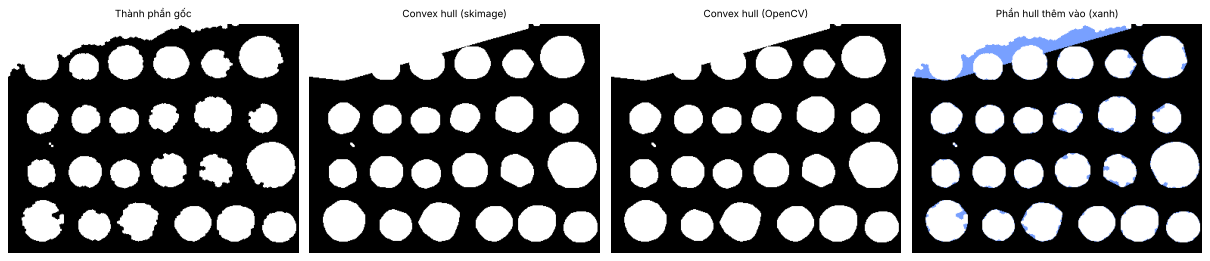

In [12]:
hull_sk = np.zeros(test.shape, bool)
hull_cv = np.zeros(test.shape, np.uint8)
sol = []
for p in props:
    m = lab8 == p.label
    h = morphology.convex_hull_image(m)
    hull_sk |= h
    cnt, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    pts = np.vstack(cnt)
    cv2.fillPoly(hull_cv, [cv2.convexHull(pts)], 255)
    sol.append(m.sum() / h.sum())
inter = (hull_sk & (hull_cv > 0)).sum()
union = (hull_sk | (hull_cv > 0)).sum()
print(f"IoU giữa hai cách tính convex hull = {inter/union:.4f}")
print("Solidity từng thành phần: min = %.3f, max = %.3f, TB = %.3f" % (min(sol), max(sol), np.mean(sol)))
ov = cv2.cvtColor(test, cv2.COLOR_GRAY2RGB)
ov[hull_sk & (test == 0)] = (120, 160, 255)
show([test, hull_sk, hull_cv, ov], ["Thành phần gốc", "Convex hull (skimage)", "Convex hull (OpenCV)", "Phần hull thêm vào (xanh)"],
     ncols=4, cell=3.8, name="b2_hull.png")

### (5) Thinning (làm mảnh) - ảnh chữ in `page.png`
Ngưỡng thích nghi tách nét chữ, sau đó `skimage.morphology.thin` (thinning) và `skeletonize` (xương) để so sánh.

Số pixel nét chữ: 84224 | sau thinning: 14104 | skeletonize: 14489
Tỉ lệ giữ lại: thinning = 16.7%, skeleton = 17.2%


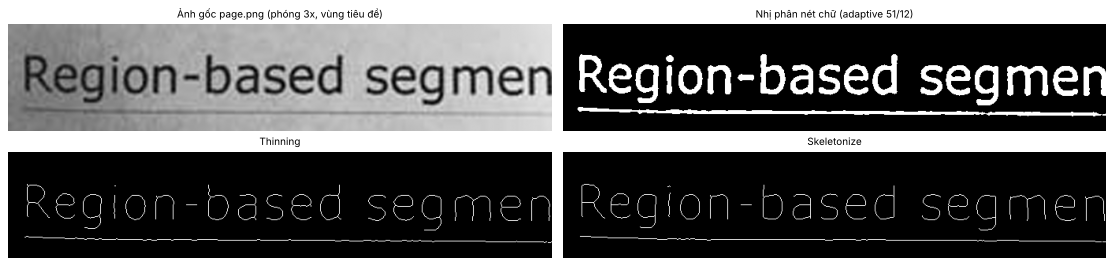

In [13]:
page = load_gray("page.png", data.page)
text = cv2.resize(page, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC)        # phóng 3x để nét chữ đủ dày
tbw = cv2.adaptiveThreshold(text, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 51, 12)
n_cc, cc, st, _ = cv2.connectedComponentsWithStats(tbw, connectivity=8)
keep = st[:, cv2.CC_STAT_AREA] >= 30
keep[0] = False                                                                   # nhãn 0 = nền
tbw = keep[cc].astype(np.uint8) * 255                                             # bỏ hạt nhiễu < 30 px
thin = morphology.thin(tbw > 0)
skel = morphology.skeletonize(tbw > 0)
print("Số pixel nét chữ:", int((tbw > 0).sum()), "| sau thinning:", int(thin.sum()), "| skeletonize:", int(skel.sum()))
print("Tỉ lệ giữ lại: thinning = %.1f%%, skeleton = %.1f%%" % (100 * thin.sum() / (tbw > 0).sum(), 100 * skel.sum() / (tbw > 0).sum()))
crop = (slice(0, 135), slice(0, 690))
show([text[crop], tbw[crop], thin[crop], skel[crop]], ["Ảnh gốc page.png (phóng 3x, vùng tiêu đề)", "Nhị phân nét chữ (adaptive 51/12)", "Thinning", "Skeletonize"],
     ncols=2, cell=7, name="b2_thinning.png")

**Nhận xét 2.3**
* **Hình bao:** SE `rect 3×3` cho 5 364 px (đường biên dày, 4-liên thông), SE `cross 3×3` cho 3 897 px (mỏng hơn, 8-liên thông). Cả hai trùng 100% (0 pixel khác biệt) với `skimage.segmentation.find_boundaries(mode='inner')` tương ứng.
* **Làm đầy lỗ:** thuật toán dựng nền từ biên ảnh hội tụ sau 205 vòng, lấp 956 px lỗ (do vân đồng xu thấp hơn ngưỡng Otsu) và trùng 100% với `scipy.ndimage.binary_fill_holes`. Số vòng lớn vì nền lan 1 px mỗi vòng với SE chữ thập; không cần chọn điểm hạt cho từng lỗ.
* **Thành phần liên thông:** tự lập trình cho 26 thành phần (8-liên thông) và 27 thành phần (4-liên thông) - hơn 1 vì hai khối 3×3 đặt chạm nhau ở góc chéo chỉ dính nhau theo 8-liên thông; phân hoạch trùng `cv2.connectedComponents` ở cả hai kiểu. 23 thành phần có diện tích 1 074 - 3 024 px là các đồng xu; thành phần 8 473 px là vùng nền sáng ở mép trên **dính cả đồng xu góc trên-trái** (do ngưỡng Otsu); 18 px là cặp khối thử và 23 px là một hạt nhỏ. Bản morphological mất ~0,7 s cho hai lượt (lặp giãn theo từng thành phần) - chậm hơn nhiều so với duyệt hai lượt của OpenCV nhưng cho đúng kết quả.
* **Convex hull:** hai cách tính (skimage, OpenCV) trùng IoU = 0,997. Độ đặc (solidity) trung bình 0,929 (0,636 - 0,972): đồng xu gần lồi nên cao; vùng nền sáng mép trên có hình lõm nên thấp nhất (0,636); đồng xu bị khuyết/có vết lõm thấp hơn các đồng xu tròn.
* **Thinning (trang chữ in, phóng 3×):** 84 224 px nét chữ -> 14 104 px (16,7%) với `thin` và 14 489 px (17,2%) với `skeletonize`. Cả hai cho nét dày 1 px, giữ được hình dạng và tính liên thông của chữ; skeleton có thêm vài nhánh cụt nhỏ nên nhiều điểm hơn chút. Kết quả phụ thuộc chất lượng nhị phân hóa (ảnh gốc chữ mảnh nên phải phóng 3× và dùng adaptive threshold, nếu dùng opening 3×3 như thử ban đầu thì các nét chữ mỏng bị xóa).